Google Drive & Locate Dataset

In [ ]:
import os, glob
from google.colab import drive

drive.mount('/content/drive')

matches = glob.glob('/content/drive/MyDrive/**/ai_ds_job_salaries_2026_5000x16*.csv', recursive=True)

if matches:
    DATASET_PATH = matches[0]
    os.chdir(os.path.dirname(DATASET_PATH))
    print("Dataset Found:", DATASET_PATH)
else:
    DATASET_PATH = 'ai_ds_job_salaries_2026_5000x16.csv'
    print("Using local path:", DATASET_PATH)

Mounted at /content/drive
Dataset Found: /content/drive/MyDrive/DS1/ai_ds_job_salaries_2026_5000x16.csv


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
data = pd.read_csv(os.path.basename(DATASET_PATH))

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
data.head(10)

,job_title,experience_level,employment_type,company_size,company_location,industry,remote_ratio,years_experience,education_level,primary_language,manages_people,certifications_count,weekly_hours,ai_tools_hours_per_week,job_satisfaction_score,salary_usd
0,Data Analyst,Lead,Part-time,S,IN,Finance,0,14.4,Bachelors,Python,True,0,48.0,12.5,5.5,23844
1,Research Scientist,Senior,Full-time,L,US,Retail,50,7.6,Masters,SQL,False,1,41.6,2.1,7.0,170132
2,Machine Learning Engineer,Entry,Full-time,M,US,Government,0,0.0,Bootcamp,Python,False,1,55.1,5.1,5.9,83059
3,Data Engineer,Senior,Full-time,M,BR,Government,100,9.7,Masters,Java,False,2,41.1,2.0,5.6,29531
4,Data Engineer,Mid,Full-time,M,US,Education,0,3.2,Bachelors,Python,False,2,48.2,4.0,4.6,70105
5,Analytics Engineer,Senior,Full-time,M,SG,Finance,100,11.6,Masters,Python,False,1,54.6,17.4,7.9,97827
6,Business Intelligence Analyst,Senior,Full-time,M,US,Technology,0,9.8,Bachelors,Python,False,1,48.4,0.5,5.5,120062
7,Data Analyst,Entry,Full-time,M,US,Retail,0,1.4,Masters,Python,False,3,49.8,4.2,7.3,64165
8,Research Scientist,Mid,Full-time,M,AU,Finance,0,2.2,Masters,Python,False,3,36.1,6.6,7.7,112968
9,Data Engineer,Entry,Part-time,L,GB,Healthcare,0,2.8,Self-taught,SQL,False,2,44.8,2.0,6.2,26464


In [ ]:
print("Dataset Shape:", data.shape)

Dataset Shape: (5000, 16)


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   job_title                5000 non-null   object 
 1   experience_level         5000 non-null   object 
 2   employment_type          5000 non-null   object 
 3   company_size             5000 non-null   object 
 4   company_location         5000 non-null   object 
 5   industry                 5000 non-null   object 
 6   remote_ratio             5000 non-null   int64  
 7   years_experience         5000 non-null   float64
 8   education_level          5000 non-null   object 
 9   primary_language         5000 non-null   object 
 10  manages_people           5000 non-null   bool   
 11  certifications_count     5000 non-null   int64  
 12  weekly_hours             5000 non-null   float64
 13  ai_tools_hours_per_week  5000 non-null   float64
 14  job_satisfaction_score  

In [ ]:
data.describe()

,remote_ratio,years_experience,certifications_count,weekly_hours,ai_tools_hours_per_week,job_satisfaction_score,salary_usd
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.08000,8.361440,1.820400,44.345400,8.437400,6.685320,98605.406200
std,41.45428,4.820808,1.344212,6.142761,5.503637,1.364302,55369.310473
min,0.00000,0.000000,0.000000,24.400000,0.000000,1.100000,12000.000000
25%,0.00000,4.800000,1.000000,40.100000,3.300000,5.800000,55592.750000
50%,50.00000,8.100000,2.000000,44.400000,8.500000,6.700000,90572.000000
75%,100.00000,11.500000,3.000000,48.500000,12.625000,7.600000,129657.750000
max,100.00000,23.700000,8.000000,67.300000,25.200000,10.000000,372347.000000


**Exploratory Data Analysis (EDA)**

In [ ]:
print("Column Names:")
print(data.columns.tolist())

print("\nData Types:")
print(data.dtypes)

Column Names:
['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'remote_ratio', 'years_experience', 'education_level', 'primary_language', 'manages_people', 'certifications_count', 'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score', 'salary_usd']

Data Types:
job_title                   object
experience_level            object
employment_type             object
company_size                object
company_location            object
industry                    object
remote_ratio                 int64
years_experience           float64
education_level             object
primary_language            object
manages_people                bool
certifications_count         int64
weekly_hours               float64
ai_tools_hours_per_week    float64
job_satisfaction_score     float64
salary_usd                   int64
dtype: object


In [ ]:
for column in data.columns:
    print(f"\n{column}:")
    print(data[column].unique()[:10])


job_title:
['Data Analyst' 'Research Scientist' 'Machine Learning Engineer'
 'Data Engineer' 'Analytics Engineer' 'Business Intelligence Analyst'
 'Data Science Manager' 'Computer Vision Engineer' 'LLM Engineer'
 'Data Scientist']

experience_level:
['Lead' 'Senior' 'Entry' 'Mid' 'Executive']

employment_type:
['Part-time' 'Full-time' 'Contract' 'Freelance']

company_size:
['S' 'L' 'M']

company_location:
['IN' 'US' 'BR' 'SG' 'AU' 'GB' 'FR' 'DE' 'PL' 'NL']

industry:
['Finance' 'Retail' 'Government' 'Education' 'Technology' 'Healthcare'
 'Consulting' 'Media' 'Manufacturing' 'Energy']

remote_ratio:
[  0  50 100]

years_experience:
[14.4  7.6  0.   9.7  3.2 11.6  9.8  1.4  2.2  2.8]

education_level:
['Bachelors' 'Masters' 'Bootcamp' 'Self-taught' 'PhD']

primary_language:
['Python' 'SQL' 'Java' 'R' 'Julia' 'Scala' 'Rust']

manages_people:
[ True False]

certifications_count:
[0 1 2 3 4 6 5 8 7]

weekly_hours:
[48.  41.6 55.1 41.1 48.2 54.6 48.4 49.8 36.1 44.8]

ai_tools_hours_per_week

count      5000.000000
mean      98605.406200
std       55369.310473
min       12000.000000
25%       55592.750000
50%       90572.000000
75%      129657.750000
max      372347.000000
Name: salary_usd, dtype: float64


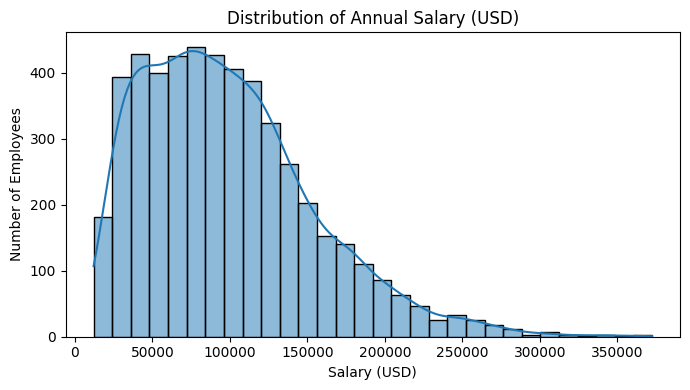

In [ ]:
print(data['salary_usd'].describe())

plt.figure(figsize=(7, 4))
sns.histplot(data=data, x='salary_usd', bins=30, kde=True)

plt.title('Distribution of Annual Salary (USD)')
plt.xlabel('Salary (USD)')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()

experience_level
Mid          1613
Senior       1520
Entry         985
Lead          656
Executive     226
Name: count, dtype: int64


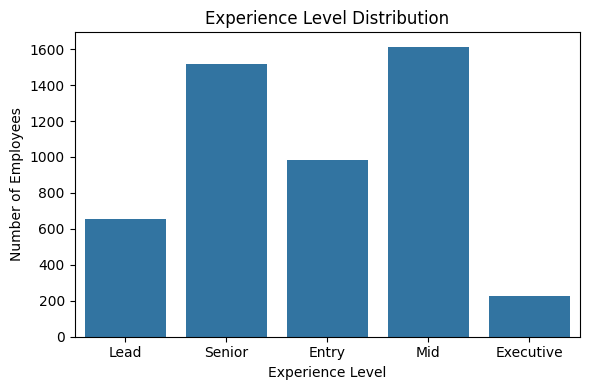

In [ ]:
# Analyze experience_level distribution
print(data['experience_level'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='experience_level')

plt.title('Experience Level Distribution')
plt.xlabel('Experience Level')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()

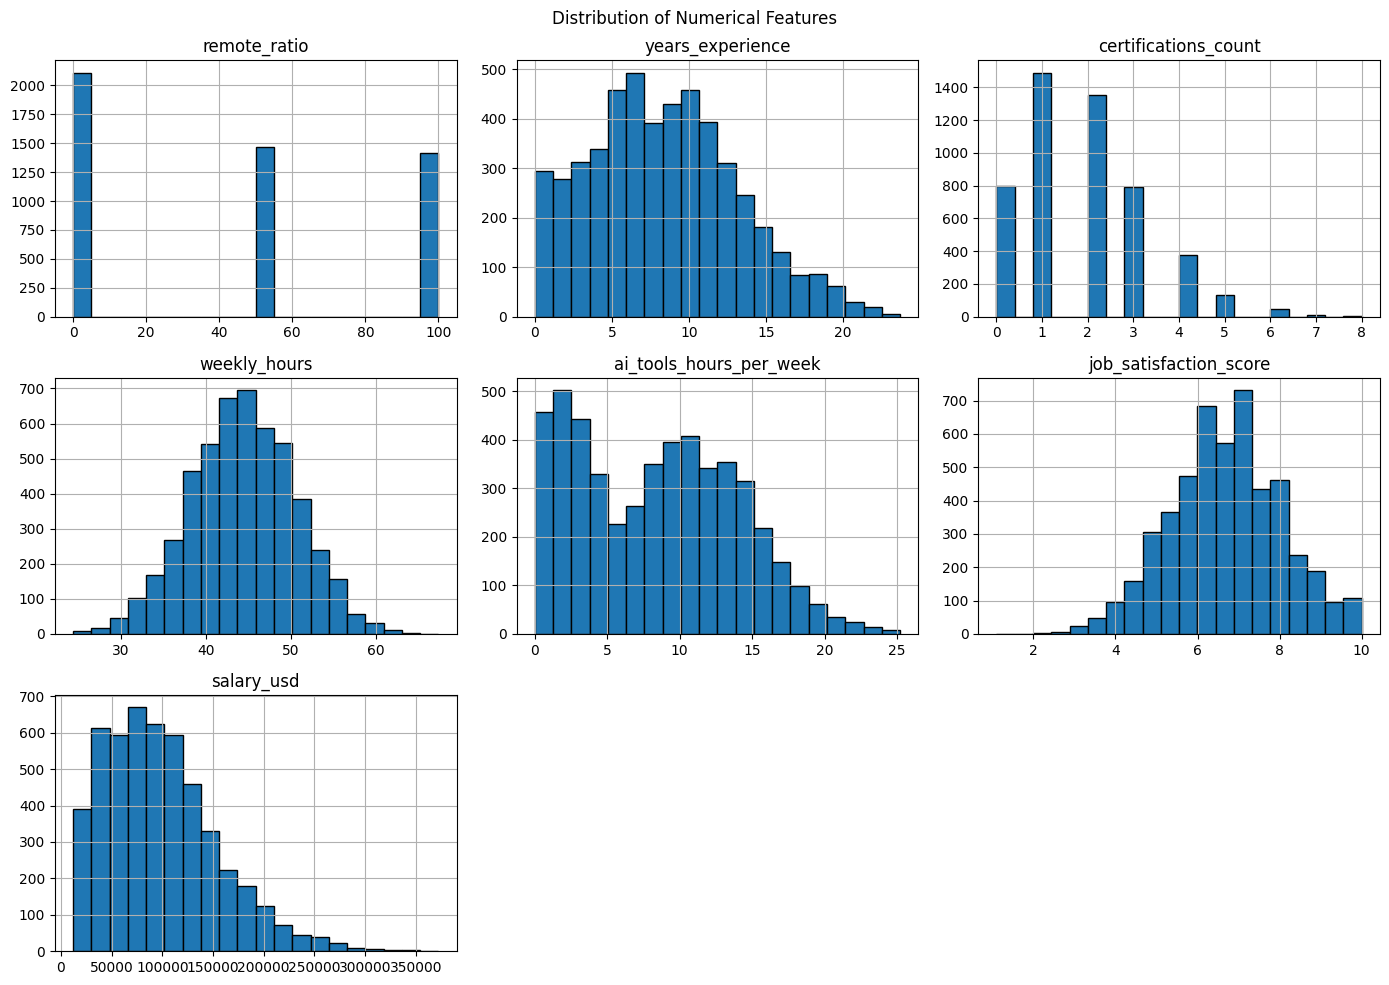

In [ ]:
#numerical feature distributions
numerical_columns = [
    'remote_ratio', 'years_experience', 'certifications_count',
    'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score',
    'salary_usd'
]

data[numerical_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

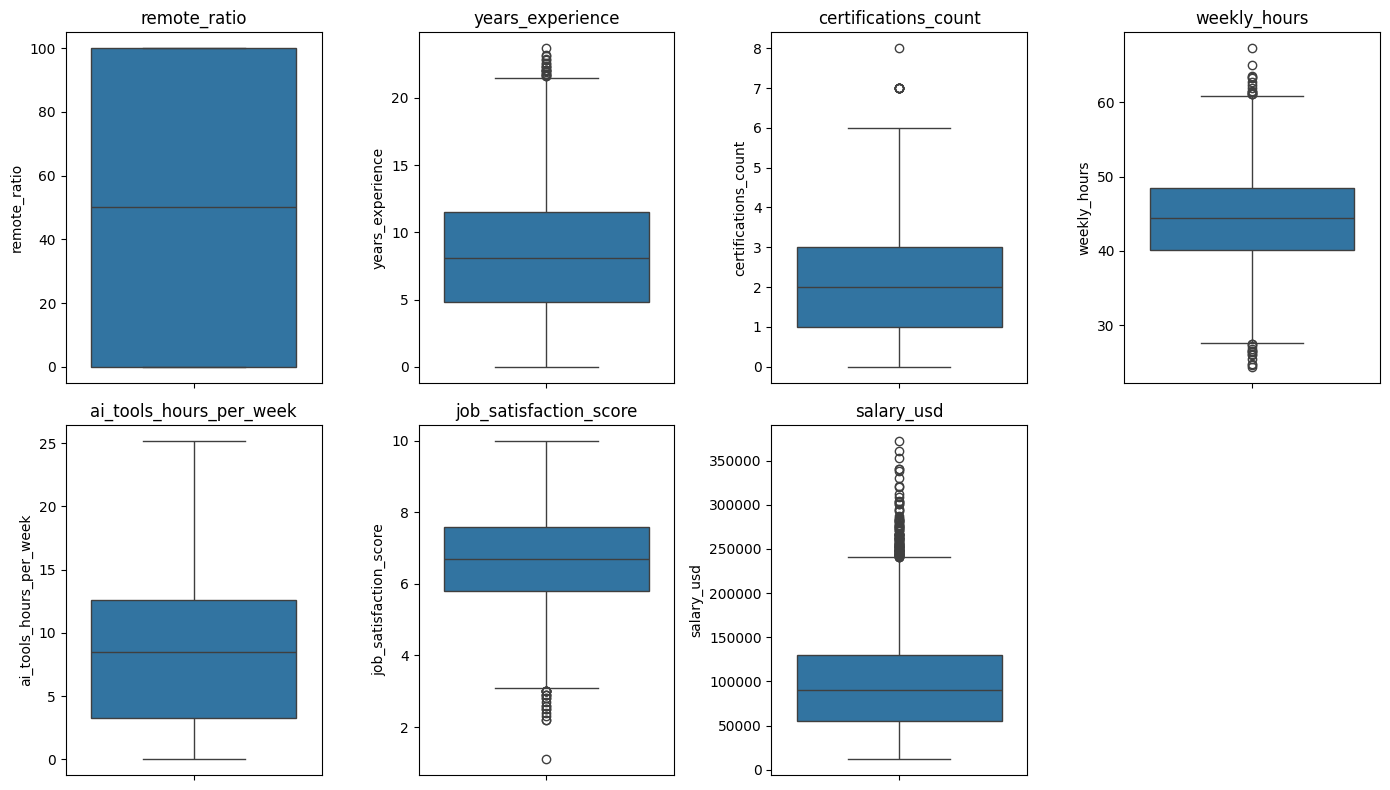

In [ ]:
# Boxplots to identify possible outliers
plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=data[column])
    plt.title(column)

plt.tight_layout()
plt.show()

Data Clean

In [ ]:
print("Missing Values in Each Column:")
print(data.isnull().sum())

print("\nTotal Missing Values:")
print(data.isnull().sum().sum())

Missing Values in Each Column:
job_title                  0
experience_level           0
employment_type            0
company_size               0
company_location           0
industry                   0
remote_ratio               0
years_experience           0
education_level            0
primary_language           0
manages_people             0
certifications_count       0
weekly_hours               0
ai_tools_hours_per_week    0
job_satisfaction_score     0
salary_usd                 0
dtype: int64

Total Missing Values:
0


In [ ]:
print("Number of Duplicate Rows:", data.duplicated().sum())

Number of Duplicate Rows: 0


In [ ]:
data = data.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(data.shape)

Dataset Shape After Removing Duplicates:
(5000, 16)


In [ ]:
print("Missing Values:")
print(data.isnull().sum().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("\nFinal Dataset Shape:")
print(data.shape)

Missing Values:
0

Duplicate Rows:
0

Final Dataset Shape:
(5000, 16)


**Data Preprocessing**

In [ ]:
df = data.copy()

print("Original Dataset Shape:", data.shape)
print("Working Dataset Shape:", df.shape)

Original Dataset Shape: (5000, 16)
Working Dataset Shape: (5000, 16)


Separate input features (X) and target variable (y)

In [ ]:
X = df.drop('salary_usd', axis=1)
y = df['salary_usd']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (5000, 15)
Target Variable Shape: (5000,)

Input Features:
['job_title', 'experience_level', 'employment_type', 'company_size', 'company_location', 'industry', 'remote_ratio', 'years_experience', 'education_level', 'primary_language', 'manages_people', 'certifications_count', 'weekly_hours', 'ai_tools_hours_per_week', 'job_satisfaction_score']


Split the dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (4000, 15)
Testing Data Shape: (1000, 15)


StandardScaler

In [ ]:
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Training Data Shape After Encoding & Scaling:", X_train_scaled.shape)
print("Testing Data Shape After Encoding & Scaling:", X_test_scaled.shape)

Training Data Shape After Encoding & Scaling: (4000, 66)
Testing Data Shape After Encoding & Scaling: (1000, 66)


Train Linear Regression

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


Train Random Forest

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest Regressor Training Completed!")

Random Forest Regressor Training Completed!


Train Gradient

In [ ]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    random_state=42
)

hgb_model.fit(X_train_scaled, y_train)

print("HistGradientBoosting Regressor Training Completed!")

HistGradientBoosting Regressor Training Completed!


In [ ]:
lr_pred = lr_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test_scaled)
hgb_pred = hgb_model.predict(X_test_scaled)

print("All predictions completed!")

print("\nLinear Regression Predictions:", np.round(lr_pred[:5], 2))
print("Random Forest Predictions:", np.round(rf_pred[:5], 2))
print("HistGradientBoosting Predictions:", np.round(hgb_pred[:5], 2))

All predictions completed!

Linear Regression Predictions: [34069.81 85092.49 26905.8  82729.32 32246.35]
Random Forest Predictions: [33953.7  75610.43 54474.05 47220.95 73710.45]
HistGradientBoosting Predictions: [38029.47 74137.11 32041.2  43050.15 42520.37]


**Model Evaluation**

In [ ]:

lr_r2 = r2_score(y_test, lr_pred)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)


rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)


hgb_r2 = r2_score(y_test, hgb_pred)
hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_mse = mean_squared_error(y_test, hgb_pred)
hgb_rmse = np.sqrt(hgb_mse)

print("Evaluation metrics calculated successfully!")

Evaluation metrics calculated successfully!


In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regressor', 'HistGradientBoosting Regressor'],
    'R2 Score': [lr_r2, rf_r2, hgb_r2],
    'MAE': [lr_mae, rf_mae, hgb_mae],
    'MSE': [lr_mse, rf_mse, hgb_mse],
    'RMSE': [lr_rmse, rf_rmse, hgb_rmse]
})

results_sorted = results.sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
print(results_sorted.round(4))

best_model_name = results_sorted.loc[0, 'Model']
best_r2 = results_sorted.loc[0, 'R2 Score']
print(f"\nBest Selected Model: {best_model_name} (R2 Score = {best_r2:.4f})")

                            Model  R2 Score         MAE           MSE  \
0  HistGradientBoosting Regressor    0.8447  15184.4404  4.724358e+08   
1               Linear Regression    0.8055  18100.6728  5.917628e+08   
2         Random Forest Regressor    0.7779  18400.7481  6.756978e+08   

         RMSE  
0  21735.5890  
1  24326.1761  
2  25994.1871  

Best Selected Model: HistGradientBoosting Regressor (R2 Score = 0.8447)


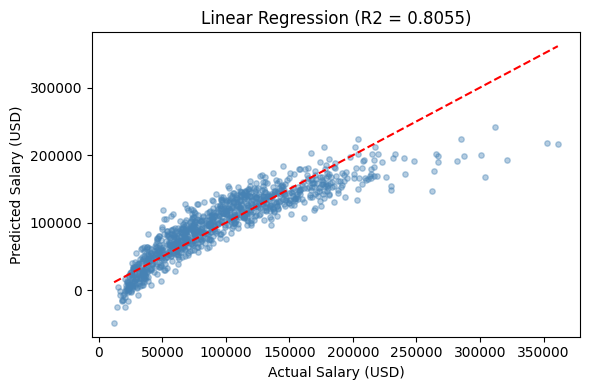

In [ ]:
# Linear Regression: Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, lr_pred, alpha=0.4, s=15, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f'Linear Regression (R2 = {lr_r2:.4f})')
plt.xlabel('Actual Salary (USD)')
plt.ylabel('Predicted Salary (USD)')
plt.tight_layout()
plt.show()

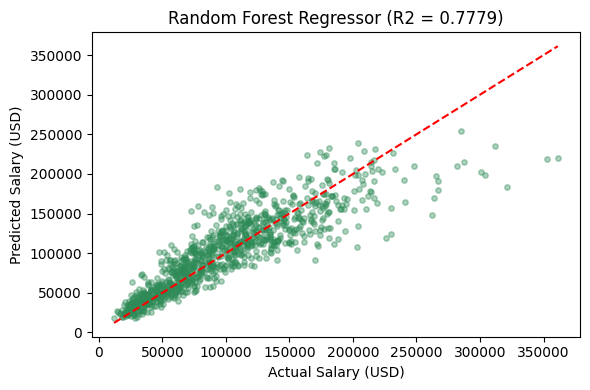

In [ ]:
# Random Forest Regressor: Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, rf_pred, alpha=0.4, s=15, color='seagreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f'Random Forest Regressor (R2 = {rf_r2:.4f})')
plt.xlabel('Actual Salary (USD)')
plt.ylabel('Predicted Salary (USD)')
plt.tight_layout()
plt.show()

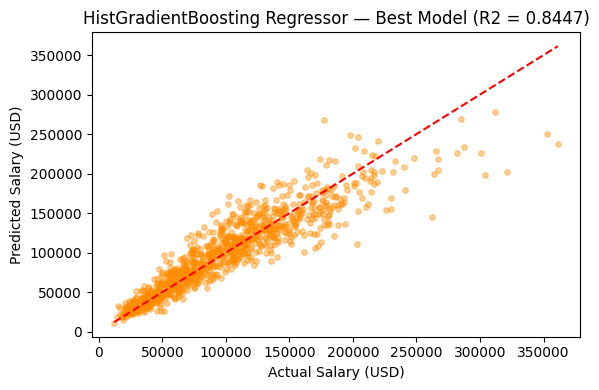

In [ ]:
# HistGradientBoosting Regressor (Best Model): Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, hgb_pred, alpha=0.4, s=15, color='darkorange')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f'HistGradientBoosting Regressor — Best Model (R2 = {hgb_r2:.4f})')
plt.xlabel('Actual Salary (USD)')
plt.ylabel('Predicted Salary (USD)')
plt.tight_layout()
plt.show()